# Preprocessing and augmentation

Load the campus image data and inspect the training transformations. This notebook previews augmentations before they are used by the model experiments.


In [1]:
from pathlib import Path
import sys

notebook_dir = Path.cwd().resolve()
if not (notebook_dir / "utils.py").is_file():
    notebook_dir = notebook_dir / "notebooks"
sys.path.insert(0, str(notebook_dir))

from utils import setup_notebook_imports
setup_notebook_imports()

import numpy as np
from src.preprocessing import load_and_split_data, augment_training_data
from src.visualization import (
    preview_full_augmentations,
    preview_mild_augmentations,
)

In [2]:
datasets = load_and_split_data()
X_train_raw = datasets["train"]["images"]
y_train = datasets["train"]["labels"]
print({name: split["images"].shape for name, split in datasets.items()})

{'train': (400, 224, 224, 3), 'validation': (101, 224, 224, 3), 'test': (126, 224, 224, 3)}


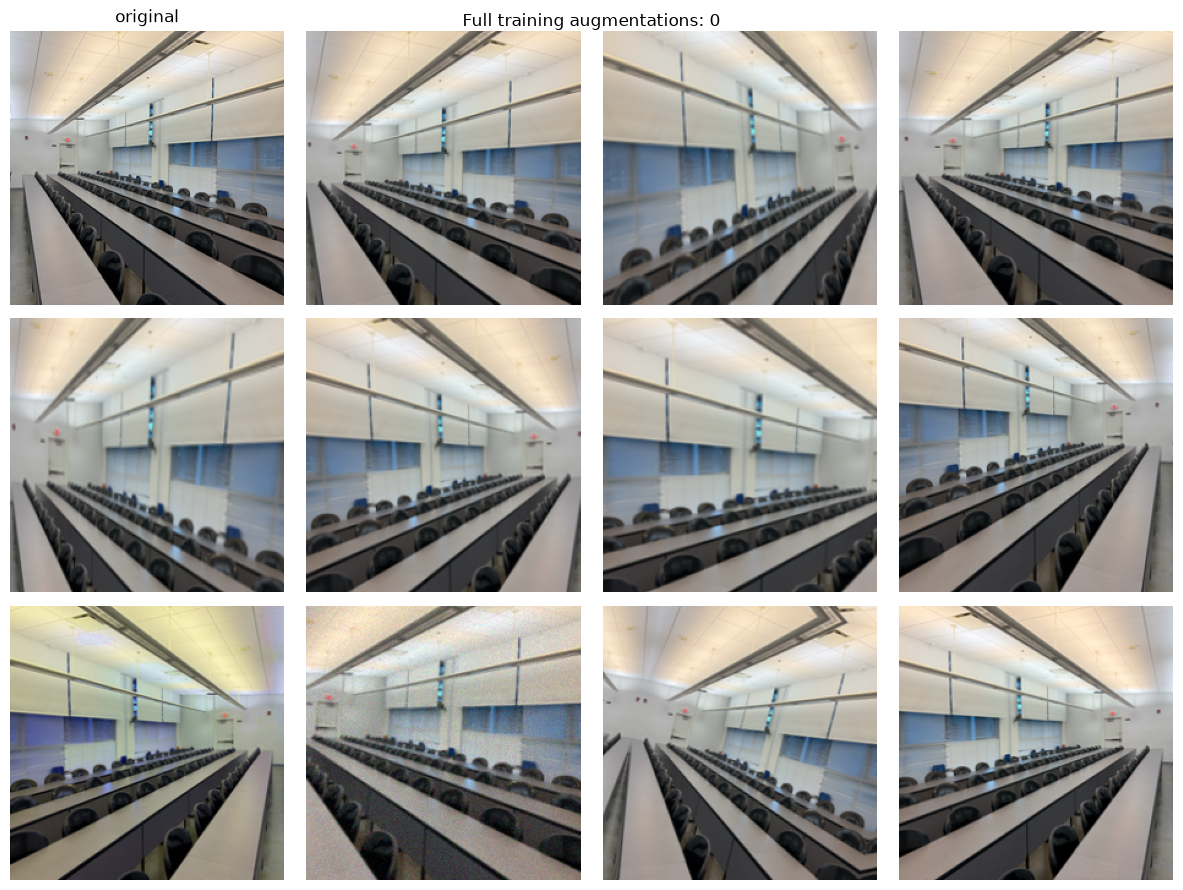

In [23]:
image_index = np.random.randint(len(X_train_raw))
preview_full_augmentations(
    X_train_raw[image_index], y_train[image_index], n=12
);

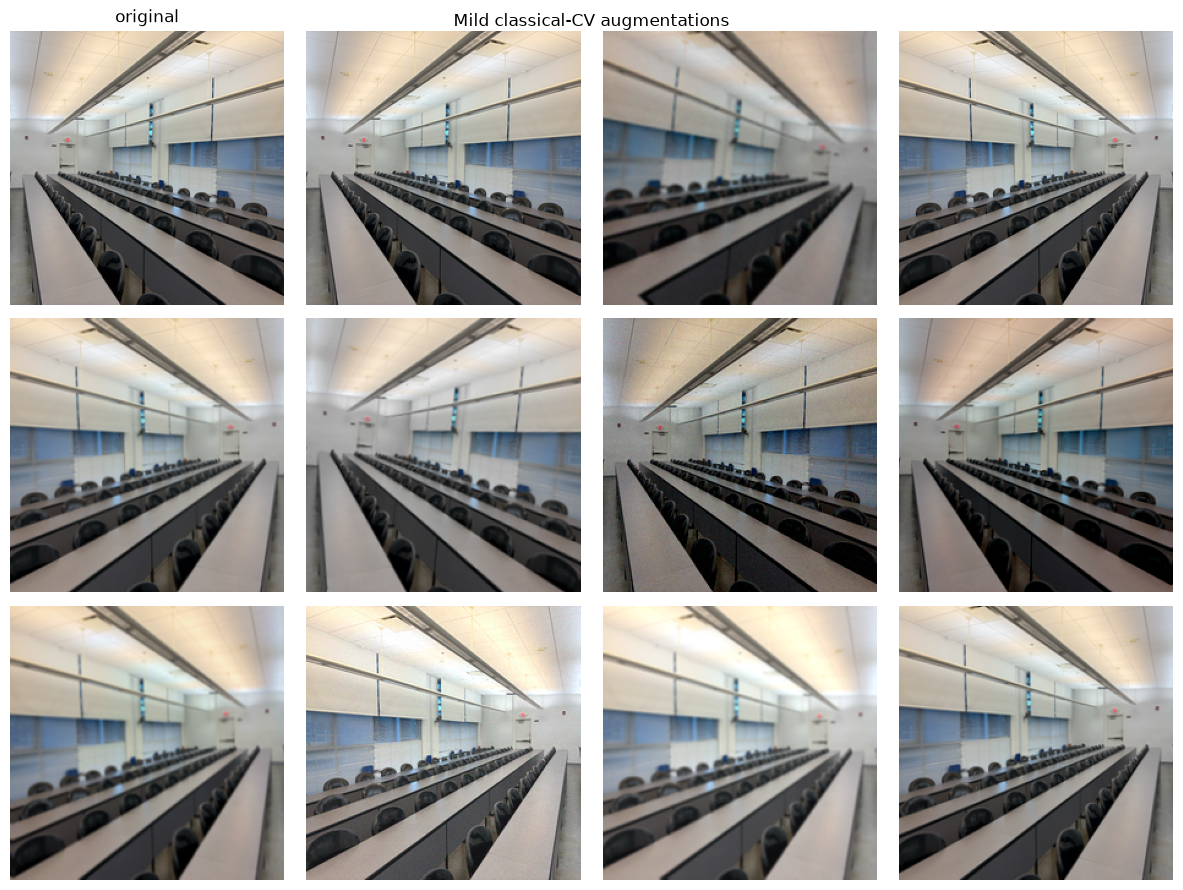

In [26]:
preview_mild_augmentations(X_train_raw[image_index], n=12);

In [27]:
X_train_epoch, y_train_epoch = augment_training_data(X_train_raw, y_train)
print(X_train_epoch.shape, X_train_epoch.dtype, y_train_epoch.shape)

(400, 224, 224, 3) float32 (400,)
